# Figure 3 (v2) — downsampling timing agreement, rebuilt with ChronoPack on r9 data

This notebook asks how much the onset and peak times of K562 + TNF-alpha response genes change
when the same experiment is sampled every 30 min instead of every 10 min.

Since 2026-11-16 v2 also builds Figure 3's other figure, the broad/fine dynamic modes (step 00,
unchanged from v1), so v2 holds both Figure 3 figures; v1 is in `../old/Fig3_DynamicModes`.

The original Figure 3 (`../old/Fig3_DynamicModes`) took these times from an old synthetic run made
with raw tradeSeq on pre-r9 data. Here both fits are redone with ChronoPack's own API on the r9
K562 + TNF-alpha cells:

| Fit | Cells | Time points | Knots |
|---|---|---|---|
| reference `K562_trunc` | 5,674 | 0–90 min, every 10 min (tags 1–10) | 8 |
| downsampled `K562_ds` | 2,582 | 0, 30, 60, 90 min (tags 1, 4, 7, 10) | 4 |

Both fits cover the 2,022 K562a genes of the r9 gene-trajectory table.

By default the notebook shows the existing outputs; set `RERUN = True` to regenerate. The
reference fit takes about 20 min, so run the notebook on a compute node.

## Setup

In [1]:
import os
import sys
from pathlib import Path

FIG_DIR = Path.cwd()  # the notebook runs from its figure folder
sys.path.insert(0, str(FIG_DIR / "scripts"))
from nb_helpers import needs_run, run, show_image, show_table, show_text

# False: show the existing outputs (steps only run if an output is missing).
# True:  regenerate every step. Batch runs can set FIG_RERUN=1 instead of editing this cell.
RERUN = os.environ.get("FIG_RERUN", "0") == "1"

CP_ENV = Path("/new-stg/home/alex/miniconda3/envs/chronopack")   # chronopack + rpy2/R (fits, predictions)
R_ENV = Path("/new-stg/home/alex/miniconda3/envs/tradeseq_ce")   # R ggplot2/patchwork (figure)
CP_PYTHON, RSCRIPT = CP_ENV / "bin" / "python", R_ENV / "bin" / "Rscript"
print("RERUN =", RERUN)

RERUN = False


## Step 00 — broad and fine dynamic modes

`00_plot_dynamic_modes_broad_fine_examples.R` is v1's step 01, unchanged, on the same r9 gene-trajectory tables
(`input/pc_df.new.csv`, `input/gene_trajectory_fit.csv`, `input/gene_trajectory_time_grid.csv`). It z-scores each
K562a fitted trajectory, then for every broad mode draws the median (line) and interquartile range (ribbon) across
its genes, next to its largest fine clusters. Each fine-cluster panel lists its three genes with the largest
tradeSeq Wald statistic. Step 04 checks that its tables equal v1's.

In [ ]:
outputs = [
    "output/dynamic_modes_v3_K562a_broad_fine_examples_v4.png",
    "output/dynamic_modes_v3_K562a_selected_fine_cluster_examples_v4.csv",
]
if needs_run(outputs, RERUN):
    run([RSCRIPT, "scripts/00_plot_dynamic_modes_broad_fine_examples.R", "K562a"], env={"FIGURE_VERSION": "v4"})
show_image(outputs[0], caption="Broad and fine dynamic modes (K562a)")
show_table(outputs[1], n=None, usecols=["broad_cluster", "fine_cluster", "n_gene_celltype", "examples"]);

## Step 01 — the two ChronoPack fits

`01_fit_downsampling.py --run <run>` does four things:
1. Subsets the r9 AnnData (`input/adata_prefiltered.1e4-variant.fixed.h5ad`) to the run's time
   points.
2. Calls `cp.tl.fit_gene_dynamics(sub, prepare_inputs=True, genes=<2,022 K562a genes>,
   final_nknots=8 or 4)`.
3. Writes the subset's tradeSeq inputs to `output/chronopack/<run>/`. Within the subset, pseudotime
   becomes (tag − 1) / 9 and the size factors become library size / mean, as in the original run.
4. Keeps the fitted model as `sce.1trajectory.nknots{k}.rds`.

In [2]:
import json
import pandas as pd

for fit_run, k in [("K562_trunc", 8), ("K562_ds", 4)]:
    if needs_run([f"output/chronopack/{fit_run}/sce.1trajectory.nknots{k}.rds"], RERUN):
        run([CP_PYTHON, "scripts/01_fit_downsampling.py", "--run", fit_run], prepend_path=CP_ENV / "bin")
meta = [json.loads((FIG_DIR / f"output/chronopack/{r}/fit_metadata.json").read_text()) for r in ["K562_trunc", "K562_ds"]]
pd.DataFrame(meta)[["run", "time_tags", "nknots", "n_cells", "n_genes", "minutes"]]

Using existing outputs (set RERUN = True to regenerate).
Using existing outputs (set RERUN = True to regenerate).


,run,time_tags,nknots,n_cells,n_genes,minutes
0,K562_trunc,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]",8,5674,2022,18.3
1,K562_ds,"[1, 4, 7, 10]",4,2582,2022,3.6


## Step 02 — curves, observed means, onset and peak

`02_predict_and_characterize.py` does three things:
1. Predicts each fit's curve and 95% band at minutes 0–90 with `cp.tl.predict_gene_dynamics`.
2. Averages the normalized counts per time point for the panel genes with
   `cp.tl.observed_gene_dynamics`.
3. Characterizes all curves together with `cp.tl.compute_gene_trajectory_descriptors`, using
   package defaults.

Onset and peak are reported in true minutes. v1 reported the grid index, which is minute + 1; the
shift cancels in the offsets.

In [3]:
step02 = [f"output/chronopack/{f}" for f in ["curves.csv", "observed_means.csv", "trajectory_descriptors.csv"]]
if needs_run(step02, RERUN):
    run([CP_PYTHON, "scripts/02_predict_and_characterize.py"], prepend_path=CP_ENV / "bin")
desc = pd.read_csv(FIG_DIR / step02[2], index_col=0)
desc[desc["gene"].isin(["NFKBIA", "CXCL1", "IRF1", "BIRC3"])].pivot(index="gene", columns="cell_type", values=["t_onset", "t_peak"])

Using existing outputs (set RERUN = True to regenerate).


t_onset             t_peak           
cell_type K562_ds K562_trunc K562_ds K562_trunc
gene                                           
BIRC3        40.0       32.0    77.0       90.0
CXCL1        10.0       16.0    51.0       44.0
IRF1         15.0       22.0    66.0       52.0
NFKBIA        7.0       13.0    52.0       46.0

## Step 03 — the timing composite

The script is the same as Fig3's: same gene selection, same r9 modes, same filters
(|peak log2FC| > 0.5, p < 0.05, q < 0.05) and same layout. It now reads step 02's tables.

The bars are the mean ± SE of |downsampled − reference| per mode. The panels show both fits (95%
bands), the per-time-point observed means, and the onset and peak markers.

Using existing outputs (set RERUN = True to regenerate).


**K562a TNF-alpha downsampling agreement (ChronoPack, r9)** — `output/publication_timing_gene_composite_dynamic_modes_v10_original_dynamic_modes_v3_p005_fcgt05_all_assigned_combined_modes_with_transient_q005_no_ybreak_vector_v2.png`

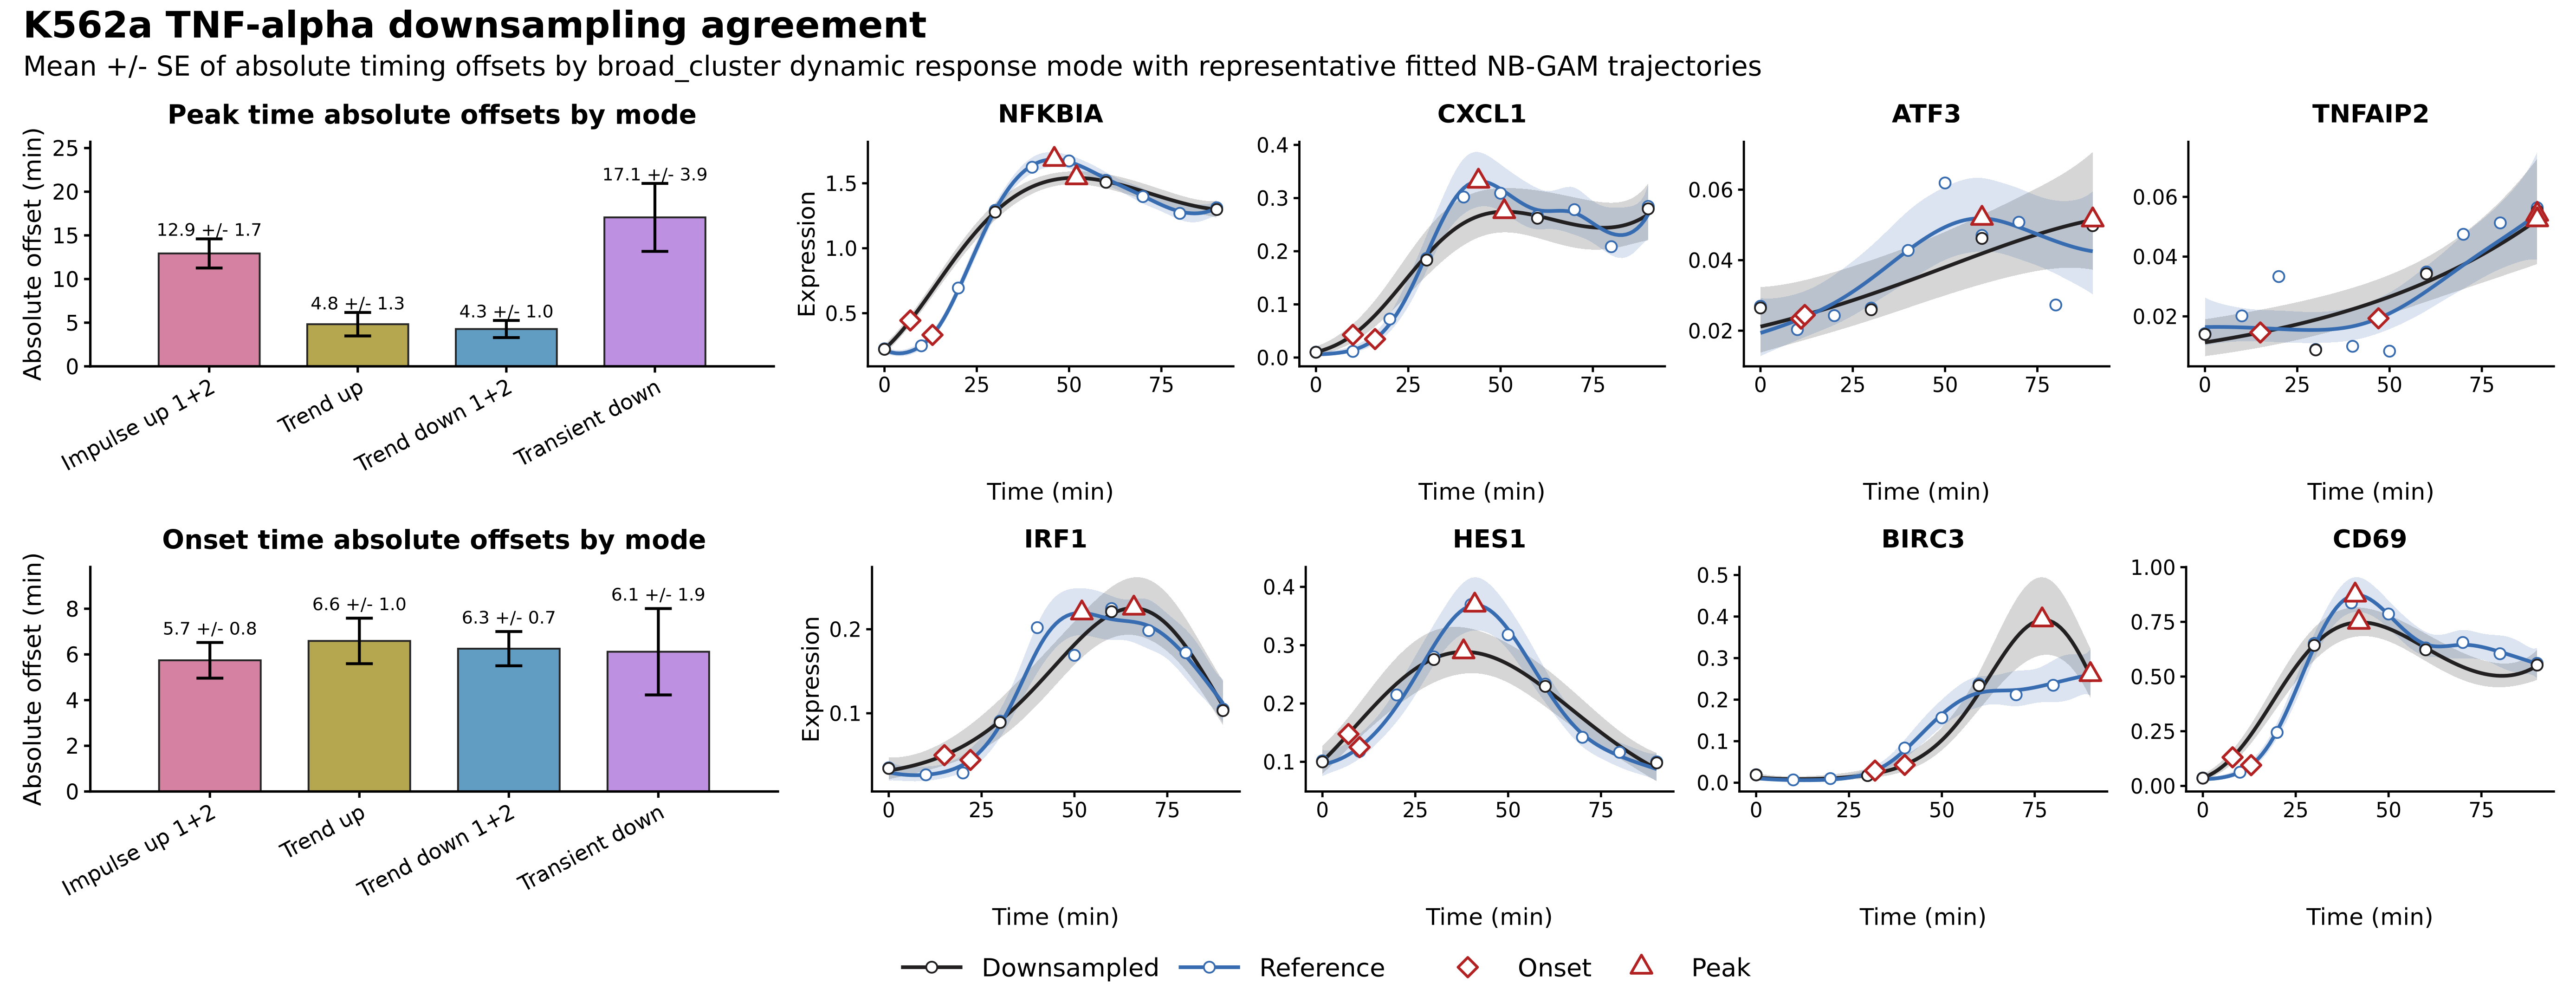

,event,dynamic_mode,n,mean_abs_offset_min,se
0,peak,impulse-up_1+2,129,12.930233,1.668768
1,peak,trend-up,109,4.825688,1.344111
2,peak,trend-down_1+2,179,4.273743,0.982740
3,peak,transient-down,17,17.058824,3.893311
4,onset,impulse-up_1+2,124,5.741935,0.780606
5,onset,trend-up,105,6.590476,0.996118
6,onset,trend-down_1+2,179,6.251397,0.749860
7,onset,transient-down,17,6.117647,1.890149


In [4]:
timing = "output/publication_timing_gene_composite_dynamic_modes_v10_original_dynamic_modes_v3_p005_fcgt05_all_assigned_combined_modes_with_transient_q005_no_ybreak_vector_v2"
timing_env = {"REQUIRE_QVALUE": "true", "USE_BREAK_AXIS": "false", "OUTPUT_SUFFIX_EXTRA": "_q005_no_ybreak"}
if needs_run([timing + ".png", timing + "_mode_summary.csv"], RERUN):
    run([RSCRIPT, "scripts/03_make_timing_composite.R"], env=timing_env)
show_image(timing + ".png", caption="K562a TNF-alpha downsampling agreement (ChronoPack, r9)")
show_table(timing + "_mode_summary.csv", n=None);

## Step 04 — comparison with v1

The report has four parts:
- **Bars:** v2's bars vs v1's.
- **Per-gene timing:** onset and peak for the genes in both versions.
- **Reference-fit check:** v2's 0–90 min reference curves vs r9's full 0–110 min fit.

v2 includes 434 genes vs v1's 317. All 434 pass the same r9 filters, but 117 of them were never
fitted in the old synthetic run, so v1 silently dropped them.
- **Modes figure:** step 00's tables must equal v1's (the step fails otherwise); PNG pixels are compared.

In [5]:
if needs_run(["output/comparison_to_v1.txt"], RERUN):
    run([CP_PYTHON, "scripts/04_compare_to_v1.py"], prepend_path=CP_ENV / "bin")
show_text("output/comparison_to_v1.txt")

Using existing outputs (set RERUN = True to regenerate).
